In [ ]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import rcParams
import seaborn as sns
%matplotlib inline 
import plotly.express as px
import plotly.graph_objs as go
import plotly.figure_factory as ff
from plotly import tools
from plotly.offline import download_plotlyjs, init_notebook_mode, plot, iplot

init_notebook_mode(connected=True)

# import re
# import random

from sklearn.datasets import make_classification
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler
from imblearn.over_sampling import SMOTE
from sklearn.utils.class_weight import compute_class_weight

import gc
from datetime import datetime 
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score, classification_report, recall_score, precision_score, f1_score, matthews_corrcoef, average_precision_score
import sklearn.metrics as metrics
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from catboost import CatBoostClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.neighbors import KNeighborsClassifier

import lightgbm as lgb
from lightgbm import LGBMClassifier
import xgboost as xgb
from sklearn import svm

import category_encoders as ce

from IPython.display import HTML
import warnings

import string


pd.set_option('display.max_columns', 100)


RFC_METRIC = 'gini'  #metric used for RandomForrestClassifier
NUM_ESTIMATORS = 100 #number of estimators used for RandomForrestClassifier
NO_JOBS = 4 #number of parallel jobs used for RandomForrestClassifier


#TRAIN/VALIDATION/TEST SPLIT
#VALIDATION
VALID_SIZE = 0.20 # simple validation using train_test_split
TEST_SIZE = 0.20 # test size using_train_test_split

#CROSS-VALIDATION
NUMBER_KFOLDS = 5 #number of KFolds for cross-validation



RANDOM_STATE = 1200

# D6 (Revision_Plan_V02.md): "temporal" is the adopted primary design -- a
# chronological 64/16/20 cut on trans_time. "random" reproduces the submitted
# shuffled split and is kept only to quantify the leakage it introduces.
SPLIT_MODE = "temporal"

MAX_ROUNDS = 1000 #lgb iterations
EARLY_STOP = 50 #lgb early stop 
OPT_ROUNDS = 1000  #To be adjusted based on best validation rounds
VERBOSE_EVAL = 50 #Print out metric result

IS_LOCAL = False

warnings.filterwarnings('default') # enable Python warnings in this file

In [ ]:
import os
from pathlib import Path

# Run from the project directory, the one containing fraudTrain_encoded.csv.
path = str(Path.cwd()) + os.sep
if not (Path(path) / "fraudTrain_encoded.csv").exists():
    print("fraudTrain_encoded.csv not found: start Jupyter in the project directory")
os.chdir(path)
print("working directory:", path)


#### Read CSV and Check

In [3]:
df_enc = pd.read_csv(path+"fraudTrain_encoded.csv")

df_enc

,trans_time,trans_time_grp,category_1,category_2,category_3,category_4a,category_4b,category_4c,category_interaction_1,category_interaction_2,amt,gender,city_1,city_2,city_3,city_4a,city_4b,state_x,state_y,city_pop,job_1,job_2,job_3,job_4,cardholder_age,loc_cluster_issue,loc_cluster_transac,issue_transac_dist,is_fraud
0,0.0,0,1,0,3,0,0,1,0,0,4.97,0,0,2,1,3,0,7,4,3495,2,2,4,2,30,346,346,78.773821,0
1,0.0,0,0,1,3,0,0,0,3,0,107.23,0,1,4,0,0,0,0,0,149,1,2,2,4,40,623,623,30.216618,0
2,0.0,0,0,0,2,0,1,0,0,0,220.11,1,2,0,1,4,1,1,0,4154,1,2,3,3,56,464,496,108.102912,0
3,0.0,0,0,1,2,0,0,0,2,0,45.00,1,3,0,2,0,2,2,0,1939,3,2,4,2,51,560,560,95.685115,0
4,0.0,0,0,0,1,0,0,1,0,0,41.96,1,1,0,0,0,0,7,3,99,0,1,2,0,32,411,411,77.702395,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1296670,12900.0,1,0,0,2,0,1,0,0,0,15.56,1,2,1,2,3,4,1,2,258,2,2,3,4,58,368,369,119.696415,0
1296671,12900.0,1,0,1,0,0,1,0,0,0,51.70,1,2,3,2,0,3,8,8,100,2,1,2,2,40,411,411,75.202184,0
1296672,12900.0,1,0,1,0,0,1,0,0,0,105.93,1,0,4,0,0,1,2,3,899,3,1,3,3,52,274,307,98.987927,0
1296673,12900.0,1,0,1,0,0,1,0,0,0,74.90,1,3,4,1,2,2,3,1,1126,1,2,3,2,39,499,499,84.688356,0


In [4]:
print("Credit Card Fraud Detection data -  rows:",df_enc.shape[0]," columns:", df_enc.shape[1])

Credit Card Fraud Detection data -  rows: 1296675  columns: 29


#### Set Train and Test features and data

In [5]:
df_enc.columns

Index(['trans_time', 'trans_time_grp', 'category_1', 'category_2',
       'category_3', 'category_4a', 'category_4b', 'category_4c',
       'category_interaction_1', 'category_interaction_2', 'amt', 'gender',
       'city_1', 'city_2', 'city_3', 'city_4a', 'city_4b', 'state_x',
       'state_y', 'city_pop', 'job_1', 'job_2', 'job_3', 'job_4',
       'cardholder_age', 'loc_cluster_issue', 'loc_cluster_transac',
       'issue_transac_dist', 'is_fraud'],
      dtype='object')

In [ ]:
target = 'is_fraud'
predictors = ['trans_time', 'trans_time_grp',
       'category_1', 'category_2','category_3',
       'category_4a', 'category_4b', 'category_4c',
       'category_interaction_1', 'category_interaction_2',
       'amt', 'gender',
       'city_1', 'city_2', 'city_3', 'city_4a', 'city_4b',
       'state_x', 'state_y', 'job_1', 'job_2', 'job_3', 'job_4', 'city_pop',
       'loc_cluster_issue', 'loc_cluster_transac', 'issue_transac_dist',
       'cardholder_age']

# D6: one split helper, used everywhere, so train/valid can never drift apart
# between the sweep loops. trans_time is hours since the first transaction, a
# monotone transform of unix_time, so cutting on it is equivalent to cutting on
# the timestamp. The cut is on the value rather than the row index, so no hour
# straddles a boundary.
def make_split(mode=None):
    mode = mode or SPLIT_MODE
    if mode == "random":
        tr, te = train_test_split(df_enc, test_size=TEST_SIZE,
                                  random_state=RANDOM_STATE, shuffle=True)
        tr, va = train_test_split(tr, test_size=VALID_SIZE,
                                  random_state=RANDOM_STATE, shuffle=True)
        return tr, va, te
    if mode == "temporal":
        t = df_enc["trans_time"]
        c1, c2 = t.quantile(0.64), t.quantile(0.80)
        return df_enc[t <= c1], df_enc[(t > c1) & (t <= c2)], df_enc[t > c2]
    raise ValueError(f"unknown SPLIT_MODE: {mode}")


train_df, valid_df, test_df = make_split()
print(f"{SPLIT_MODE} split -> train {len(train_df)}, valid {len(valid_df)}, test {len(test_df)}")
print("fraud:", int(train_df[target].sum()), int(valid_df[target].sum()), int(test_df[target].sum()))


In [7]:
train_df[target].value_counts()

is_fraud
0    825094
1      4778
Name: count, dtype: int64

In [8]:
train_df

,trans_time,trans_time_grp,category_1,category_2,category_3,category_4a,category_4b,category_4c,category_interaction_1,category_interaction_2,amt,gender,city_1,city_2,city_3,city_4a,city_4b,state_x,state_y,city_pop,job_1,job_2,job_3,job_4,cardholder_age,loc_cluster_issue,loc_cluster_transac,issue_transac_dist,is_fraud
1218083,12233.0,2,0,0,2,0,1,0,0,0,45.81,1,0,4,0,1,1,6,5,3996,0,1,1,0,42,312,345,101.304783,0
362106,4017.0,1,0,1,3,0,0,0,3,0,72.48,0,3,3,2,4,0,7,3,863,0,2,3,3,46,411,411,113.694538,0
20192,295.0,0,0,1,2,0,0,0,2,0,66.73,0,2,1,2,1,1,4,0,136,0,1,2,1,18,598,631,75.676327,0
850789,8368.0,2,1,0,3,0,0,1,0,0,2.88,1,3,3,2,4,4,3,5,1595797,1,1,1,0,24,213,212,70.993510,0
1273364,12699.0,0,0,1,3,0,0,0,3,0,114.56,0,3,3,2,1,3,5,1,6713,1,2,4,4,74,440,472,40.262366,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
122186,1627.0,2,0,0,2,0,0,1,0,0,5.88,1,0,4,0,0,1,6,4,4729,3,2,3,3,36,345,345,56.379428,0
953321,9171.0,0,0,0,1,0,0,1,0,0,42.52,1,1,4,2,1,3,3,1,1126,1,2,3,2,39,499,500,32.330302,0
69804,987.0,0,0,1,3,0,0,0,3,0,58.74,0,3,0,2,1,4,3,5,5908,1,2,3,4,56,276,276,68.118716,0
263806,3133.0,1,0,1,0,0,1,0,0,0,1.16,1,1,1,0,2,2,8,0,3224,3,1,1,0,21,542,509,57.926366,0


In [9]:
valid_df[target].value_counts()

is_fraud
0    206240
1      1228
Name: count, dtype: int64

#### Define Functions for ML Models

In [ ]:
def ML_Models():
    """Train all eight models on train_df, score them on valid_df.

    D7 (Revision_Plan_V02.md). Rewritten from V09 in three ways:

      1. Predicted probabilities are retained for every model, so AUC-PR
         (average precision) can be recorded alongside MCC. AUC-PR is the
         selection metric the reviewer asked for at 1:173 imbalance.
      2. Every model is scored on valid_df. V08/V09 scored XGBoost and LightGBM
         on test_df, which made those two rows of class_ratio_*_V05.csv
         non-comparable with the other six.
      3. Both tables are filled in the same pass, so MCC and AUC-PR always refer
         to the identical fitted model.

    Appends a column named `ratio_name` to the globals `mcc_df` and `aucpr_df`.
    """
    y_valid = valid_df[target].values
    MCC_list, AUCPR_list = [], []
    start_time = datetime.now()
    print(start_time)

    def score(model_name, preds_proba):
        preds_proba = np.asarray(preds_proba)
        binary_preds = (preds_proba > 0.5).astype(int)
        MCC = matthews_corrcoef(y_valid, binary_preds)
        AUCPR = average_precision_score(y_valid, preds_proba)
        print(f"  {model_name}: MCC = {MCC:.6f}, AUC-PR = {AUCPR:.6f}")
        MCC_list.append(MCC)
        AUCPR_list.append(AUCPR)

    # Logistic Regression
    scaler = StandardScaler()
    X_train = scaler.fit_transform(train_df[predictors])
    X_valid = scaler.transform(valid_df[predictors])
    model = LogisticRegression(max_iter=1000, class_weight='balanced')
    model.fit(X_train, train_df[target])
    score("Logistic Regression", model.predict_proba(X_valid)[:, 1])

    # Decision Tree -- seeded; V09 left it unseeded, so it drifted between runs
    clf = DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE)
    clf.fit(train_df[predictors], train_df[target].values)
    score("Decision Tree", clf.predict_proba(valid_df[predictors])[:, 1])

    # Random Forest
    clf = RandomForestClassifier(n_jobs=NO_JOBS, random_state=RANDOM_STATE,
                                 criterion=RFC_METRIC, n_estimators=NUM_ESTIMATORS,
                                 verbose=False, class_weight='balanced')
    clf.fit(train_df[predictors], train_df[target].values)
    score("Random Forest", clf.predict_proba(valid_df[predictors])[:, 1])

    # AdaBoost
    clf = AdaBoostClassifier(random_state=RANDOM_STATE, algorithm='SAMME',
                             learning_rate=0.8, n_estimators=NUM_ESTIMATORS)
    class_weights = compute_class_weight('balanced',
                                         classes=np.unique(train_df[target].values),
                                         y=train_df[target].values)
    class_weight_dict = dict(enumerate(class_weights))
    sample_weight = np.array([class_weight_dict[c] for c in train_df[target].values])
    clf.fit(train_df[predictors], train_df[target].values, sample_weight=sample_weight)
    score("AdaBoost", clf.predict_proba(valid_df[predictors])[:, 1])

    # CatBoost
    clf = CatBoostClassifier(iterations=500, learning_rate=0.02, depth=12,
                             eval_metric='AUC', random_seed=RANDOM_STATE,
                             bagging_temperature=0.2, od_type='Iter',
                             metric_period=VERBOSE_EVAL, od_wait=100)
    clf.fit(train_df[predictors], train_df[target].values, verbose=False)
    score("CatBoost", clf.predict_proba(valid_df[predictors])[:, 1])

    # XGBoost -- scored on valid_df (V09 used test_df); 'seed', not
    # 'random_state', is the key the native xgb.train API reads
    dtrain = xgb.DMatrix(train_df[predictors], train_df[target].values)
    dvalid = xgb.DMatrix(valid_df[predictors], valid_df[target].values)
    params = {'objective': 'binary:logistic', 'eta': 0.039, 'max_depth': 2,
              'subsample': 0.8, 'colsample_bytree': 0.9, 'eval_metric': 'auc',
              'seed': RANDOM_STATE}
    model = xgb.train(params, dtrain, MAX_ROUNDS,
                      [(dtrain, 'train'), (dvalid, 'valid')],
                      early_stopping_rounds=EARLY_STOP, maximize=True,
                      verbose_eval=False)
    score("XGBoost", model.predict(dvalid))

    # LightGBM -- scored on valid_df (V09 used test_df). Feature names are
    # positional because LightGBM rejects ':' and '*' in names.
    feature_names = [f"f{i}" for i in range(len(predictors))]
    params = {'boosting_type': 'gbdt', 'objective': 'binary', 'metric': 'auc',
              'learning_rate': 0.05, 'num_leaves': 7, 'max_depth': 4,
              'min_child_samples': 100, 'max_bin': 100, 'subsample': 0.9,
              'subsample_freq': 1, 'colsample_bytree': 0.7, 'min_child_weight': 0,
              'min_split_gain': 0, 'nthread': 8, 'verbose': -1,
              'scale_pos_weight': 150, 'seed': RANDOM_STATE}
    dtrain = lgb.Dataset(train_df[predictors].values, label=train_df[target].values,
                         feature_name=feature_names)
    dvalid = lgb.Dataset(valid_df[predictors].values, label=valid_df[target].values,
                         feature_name=feature_names)
    model = lgb.train(params, dtrain, valid_sets=[dtrain, dvalid],
                      valid_names=['train', 'valid'], num_boost_round=MAX_ROUNDS,
                      callbacks=[lgb.early_stopping(stopping_rounds=2 * EARLY_STOP,
                                                    verbose=False)])
    score("LightGBM", model.predict(valid_df[predictors].values))

    # K-NN
    clf = KNeighborsClassifier(1, n_jobs=-1)
    clf.fit(train_df[predictors], train_df[target].values)
    score("K-NN", clf.predict_proba(valid_df[predictors])[:, 1])

    end_time = datetime.now()
    print(end_time)
    used_time = str(end_time - start_time)

    mcc_df[ratio_name] = MCC_list + [sum(MCC_list) / len(MCC_list), used_time]
    aucpr_df[ratio_name] = AUCPR_list + [sum(AUCPR_list) / len(AUCPR_list), used_time]
    return mcc_df, aucpr_df


In [ ]:
col_list = ["Logistic Regression", "Decision Tree", "Random Forest", "AdaBoost", "CatBoost", "XGBoost", "LightGBM", "K-NN", "Average", "Time Used"]

ratio_list = [0.0066667, 0.01, 0.02, 0.111111, 0.25, 0.428571, 0.666666, 1]
ratio_name_list = ["1:150", "1:100", "1:50", "10:90", "20:80", "30:70", "40:60", "50:50(1:1)"]

#### No Sampling

In [ ]:
target = 'is_fraud'
predictors = ['trans_time', 'trans_time_grp',
       'category_1', 'category_2','category_3',
       'category_4a', 'category_4b', 'category_4c',
       'category_interaction_1', 'category_interaction_2',
       'amt', 'gender',
       'city_1', 'city_2', 'city_3', 'city_4a', 'city_4b',
       'state_x', 'state_y', 'job_1', 'job_2', 'job_3', 'job_4', 'city_pop',
       'loc_cluster_issue', 'loc_cluster_transac', 'issue_transac_dist',
       'cardholder_age']

train_df, valid_df, test_df = make_split()
print(train_df[target].value_counts())


In [ ]:
sampling_method = "No Sampling"
mcc_df = pd.DataFrame(data={f"{sampling_method} Models": col_list})
aucpr_df = pd.DataFrame(data={f"{sampling_method} Models": col_list})

ratio_name = "No Sampling (1:173)"
nosampling_mcc_df, nosampling_aucpr_df = ML_Models()

In [ ]:
nosampling_mcc_df, nosampling_aucpr_df

#### RUS

In [ ]:
target = 'is_fraud'
predictors = ['trans_time', 'trans_time_grp',
       'category_1', 'category_2','category_3',
       'category_4a', 'category_4b', 'category_4c',
       'category_interaction_1', 'category_interaction_2',
       'amt', 'gender',
       'city_1', 'city_2', 'city_3', 'city_4a', 'city_4b',
       'state_x', 'state_y', 'job_1', 'job_2', 'job_3', 'job_4', 'city_pop',
       'loc_cluster_issue', 'loc_cluster_transac', 'issue_transac_dist',
       'cardholder_age']

train_df, valid_df, test_df = make_split()
print(train_df[target].value_counts())


In [ ]:
sampling_method = "RUS"
mcc_df = pd.DataFrame(data={f"{sampling_method} Models": col_list})
aucpr_df = pd.DataFrame(data={f"{sampling_method} Models": col_list})

for index in range(0, 8):
    ratio = ratio_list[index]
    ratio_name = ratio_name_list[index]

    print("="*20, ratio_name,"="*20)

    # Phase 1 correctness fix: re-derive the split before every ratio.
    # Previously train_df was replaced by the resampled frame and carried into
    # the next iteration, so each ratio was applied on top of the previous one
    # instead of to the original training set.
    train_df, test_df = train_test_split(df_enc, test_size=TEST_SIZE,
                                         random_state=RANDOM_STATE, shuffle=True)
    train_df, valid_df = train_test_split(train_df, test_size=VALID_SIZE,
                                          random_state=RANDOM_STATE, shuffle=True)
    
    rus = RandomUnderSampler(sampling_strategy=ratio, random_state=RANDOM_STATE) # ratio is minority to majority class
    
    X, y = rus.fit_resample(train_df[predictors], train_df[target])
    
    train_df = pd.DataFrame(X, columns=predictors)
    train_df[target] = y
    print(train_df[target].value_counts())
    
    rus_mcc_df, rus_aucpr_df = ML_Models()

In [ ]:
for _df, _base in [(rus_mcc_df, nosampling_mcc_df),
                   (rus_aucpr_df, nosampling_aucpr_df)]:
    _df.insert(1, "No Sampling (1:173)", _base.iloc[:, 1])

rus_aucpr_df


#### ROS

In [ ]:
target = 'is_fraud'
predictors = ['trans_time', 'trans_time_grp',
       'category_1', 'category_2','category_3',
       'category_4a', 'category_4b', 'category_4c',
       'category_interaction_1', 'category_interaction_2',
       'amt', 'gender',
       'city_1', 'city_2', 'city_3', 'city_4a', 'city_4b',
       'state_x', 'state_y', 'job_1', 'job_2', 'job_3', 'job_4', 'city_pop',
       'loc_cluster_issue', 'loc_cluster_transac', 'issue_transac_dist',
       'cardholder_age']

train_df, valid_df, test_df = make_split()
print(train_df[target].value_counts())


In [ ]:
sampling_method = "ROS"
mcc_df = pd.DataFrame(data={f"{sampling_method} Models": col_list})
aucpr_df = pd.DataFrame(data={f"{sampling_method} Models": col_list})

for index in range(0, 8):
    ratio = ratio_list[index]
    ratio_name = ratio_name_list[index]

    print("="*20, ratio_name,"="*20)

    # Phase 1 correctness fix: re-derive the split before every ratio.
    # Previously train_df was replaced by the resampled frame and carried into
    # the next iteration, so each ratio was applied on top of the previous one
    # instead of to the original training set.
    train_df, test_df = train_test_split(df_enc, test_size=TEST_SIZE,
                                         random_state=RANDOM_STATE, shuffle=True)
    train_df, valid_df = train_test_split(train_df, test_size=VALID_SIZE,
                                          random_state=RANDOM_STATE, shuffle=True)
    
    rus = RandomOverSampler(sampling_strategy=ratio, random_state=RANDOM_STATE) # ratio is minority to majority class
    
    X, y = rus.fit_resample(train_df[predictors], train_df[target])
    
    train_df = pd.DataFrame(X, columns=predictors)
    train_df[target] = y
    print(train_df[target].value_counts())
    
    ros_mcc_df, ros_aucpr_df = ML_Models()

In [ ]:
for _df, _base in [(ros_mcc_df, nosampling_mcc_df),
                   (ros_aucpr_df, nosampling_aucpr_df)]:
    _df.insert(1, "No Sampling (1:173)", _base.iloc[:, 1])

ros_aucpr_df


#### SMOTE

In [ ]:
target = 'is_fraud'
predictors = ['trans_time', 'trans_time_grp',
       'category_1', 'category_2','category_3',
       'category_4a', 'category_4b', 'category_4c',
       'category_interaction_1', 'category_interaction_2',
       'amt', 'gender',
       'city_1', 'city_2', 'city_3', 'city_4a', 'city_4b',
       'state_x', 'state_y', 'job_1', 'job_2', 'job_3', 'job_4', 'city_pop',
       'loc_cluster_issue', 'loc_cluster_transac', 'issue_transac_dist',
       'cardholder_age']

train_df, valid_df, test_df = make_split()
print(train_df[target].value_counts())


In [ ]:
sampling_method = "SMOTE"
mcc_df = pd.DataFrame(data={f"{sampling_method} Models": col_list})
aucpr_df = pd.DataFrame(data={f"{sampling_method} Models": col_list})

for index in range(0, 8):
    ratio = ratio_list[index]
    ratio_name = ratio_name_list[index]

    print("="*20, ratio_name,"="*20)

    # Phase 1 correctness fix: re-derive the split before every ratio.
    # Previously train_df was replaced by the resampled frame and carried into
    # the next iteration, so each ratio was applied on top of the previous one
    # instead of to the original training set.
    train_df, test_df = train_test_split(df_enc, test_size=TEST_SIZE,
                                         random_state=RANDOM_STATE, shuffle=True)
    train_df, valid_df = train_test_split(train_df, test_size=VALID_SIZE,
                                          random_state=RANDOM_STATE, shuffle=True)
    
    sm = SMOTE(sampling_strategy=ratio, random_state=RANDOM_STATE) # ratio is minority to majority class
    
    X, y = sm.fit_resample(train_df[predictors], train_df[target])
    
    train_df = pd.DataFrame(X, columns=predictors)
    train_df[target] = y
    print(train_df[target].value_counts())
    
    smote_mcc_df, smote_aucpr_df = ML_Models()

In [ ]:
for _df, _base in [(smote_mcc_df, nosampling_mcc_df),
                   (smote_aucpr_df, nosampling_aucpr_df)]:
    _df.insert(1, "No Sampling (1:173)", _base.iloc[:, 1])

smote_aucpr_df


#### Result Plots

In [ ]:
mcc_rus = list(rus_mcc_df.iloc[8, 1:])
mcc_ros = list(ros_mcc_df.iloc[8, 1:])
mcc_smote = list(smote_mcc_df.iloc[8, 1:])
print(mcc_rus, "\n", mcc_ros, "\n",mcc_smote)

time_rus = []
time_ros = []
time_smote = []
for t in list(rus_mcc_df.iloc[9, 1:]): # get time
    time_delta = datetime.strptime(t, '%H:%M:%S.%f') - datetime(1900, 1, 1)
    decimal_minutes = time_delta.total_seconds() / 60 # convert to minute
    time_rus.append(decimal_minutes)

for t in list(ros_mcc_df.iloc[9, 1:]): # get time
    time_delta = datetime.strptime(t, '%H:%M:%S.%f') - datetime(1900, 1, 1)
    decimal_minutes = time_delta.total_seconds() / 60 # convert to minute
    time_ros.append(decimal_minutes)

for t in list(smote_mcc_df.iloc[9, 1:]): # get time
    time_delta = datetime.strptime(t, '%H:%M:%S.%f') - datetime(1900, 1, 1)
    decimal_minutes = time_delta.total_seconds() / 60 # convert to minute
    time_smote.append(decimal_minutes)
    
print(time_rus, "\n", time_ros,"\n", time_smote)

ratio_label = ratio_name_list.copy()
ratio_label.insert(0, "No Sampling (1:173)")

print(ratio_label)

In [ ]:
# D7: MCC kept for continuity with the submitted version; AUC-PR is the
# metric the sampling setting is now selected on.
rus_mcc_df.to_csv("result_csv/class_ratio_rus_V06.csv")
ros_mcc_df.to_csv("result_csv/class_ratio_ros_V06.csv")
smote_mcc_df.to_csv("result_csv/class_ratio_smote_V06.csv")

rus_aucpr_df.to_csv("result_csv/class_ratio_rus_aucpr_V06.csv")
ros_aucpr_df.to_csv("result_csv/class_ratio_ros_aucpr_V06.csv")
smote_aucpr_df.to_csv("result_csv/class_ratio_smote_aucpr_V06.csv")

In [ ]:
# A2 (Revision_Plan_V02.md): the sampling setting selected on the average
# across models is not necessarily best for any individual model. This table
# reports, per model, the setting that maximises its own validation AUC-PR.
_long = []
for _method, _df in [("RUS", rus_aucpr_df), ("ROS", ros_aucpr_df), ("SMOTE", smote_aucpr_df)]:
    _t = _df.set_index(_df.columns[0]).drop(index=["Average", "Time Used"])
    for _ratio in _t.columns:
        for _model, _v in _t[_ratio].items():
            _long.append({"model": _model,
                          "method": "No sampling" if _ratio.startswith("No Sampling") else _method,
                          "ratio": _ratio, "aucpr": float(_v)})

best_setting_df = (pd.DataFrame(_long)
                   .sort_values("aucpr", ascending=False)
                   .drop_duplicates("model")
                   .set_index("model")
                   .reindex(col_list[:8]))
best_setting_df.to_csv("result_csv/best_sampling_per_model_V01.csv")
best_setting_df


~/anaconda3/envs/myenv1/lib/python3.11/site-packages/IPython/core/pylabtools.py:77: DeprecationWarning:

backend2gui is deprecated since IPython 8.24, backends are managed in matplotlib and can be externally registered.



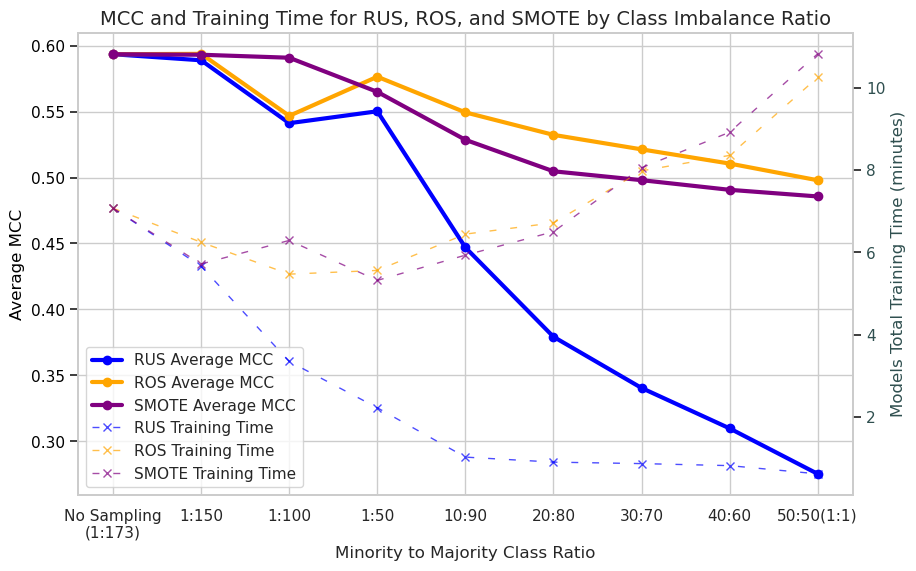

In [28]:
sns.set(style="whitegrid")

fig, ax1 = plt.subplots(figsize=(10, 6))

ratio_label[0] = "No Sampling\n(1:173)"

ax1.plot(ratio_label, mcc_rus, color='blue', marker='o', label='RUS Average MCC', linestyle='-', linewidth=3)
ax1.plot(ratio_label, mcc_ros, color='orange', marker='o', label='ROS Average MCC', linestyle='-', linewidth=3)
ax1.plot(ratio_label, mcc_smote, color='purple', marker='o', label='SMOTE Average MCC', linestyle='-', linewidth=3)
ax1.set_xlabel('Minority to Majority Class Ratio', fontsize=12)
ax1.set_ylabel('Average MCC', fontsize=12, color='black')
ax1.tick_params(axis='y', labelcolor='black')

ax2 = ax1.twinx()

ax2.plot(ratio_label, time_rus, color='blue', marker='x', label='RUS Training Time', linestyle=(0, (5, 10)), linewidth=1, alpha=0.7)
ax2.plot(ratio_label, time_ros, color='orange', marker='x', label='ROS Training Time', linestyle=(0, (5, 10)), linewidth=1, alpha=0.7)
ax2.plot(ratio_label, time_smote, color='purple', marker='x', label='SMOTE Training Time', linestyle=(0, (5, 10)), linewidth=1, alpha=0.7)
ax2.set_ylabel('Models Total Training Time (minutes)', fontsize=12, color='darkslategrey')
ax2.tick_params(axis='y', labelcolor='darkslategrey')

plt.title('MCC and Training Time for RUS, ROS, and SMOTE by Class Imbalance Ratio', fontsize=14)
ax1.grid(True)
ax2.grid(False)

lines_labels = [ax.get_legend_handles_labels() for ax in [ax1, ax2]]
lines, labels = [sum(lol, []) for lol in zip(*lines_labels)]
# ax1.legend(lines, labels, loc="upper left")
ax1.legend(lines, labels, loc="best")

plt.show()